## 1、构建流程

In [1]:
from operator import add
from typing import TypedDict, Annotated, Literal
import asyncio
import os
from langchain_mcp_adapters.client import MultiServerMCPClient
from langchain_community.chat_models import ChatTongyi # pip install dashscope
from langgraph.config import get_stream_writer
from langgraph.constants import START, END
from langgraph.graph import StateGraph
from pydantic import BaseModel, Field
from langgraph.types import Send
from langchain.chat_models import init_chat_model
from langchain.agents import create_agent
from langchain_community.embeddings import DashScopeEmbeddings # pip install langchain-community
from langchain_chroma import Chroma # pip install langchain-chroma
from langchain_core.prompts import ChatPromptTemplate
from langchain_typesafe import Choice, TypeSafeClassifier # pip install langchain-typesafe
from dotenv import load_dotenv
load_dotenv() # 从 .env 文件加载环境变量

C:\Users\Silenceing\AppData\Local\Temp\ipykernel_7316\848036862.py:6: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.chat_models import ChatTongyi # pip install dashscope


True

In [2]:
router_llm = ChatTongyi(model="qwen-plus")
router_llm.invoke("hello")

AIMessage(content='Hello! How can I help you today? 😊', additional_kwargs={}, response_metadata={'model_name': 'qwen-plus', 'finish_reason': 'stop', 'request_id': '5234b8a8-526d-9a76-9649-764d8d391b66', 'token_usage': {'input_tokens': 9, 'output_tokens': 11, 'total_tokens': 20, 'prompt_tokens_details': {'cached_tokens': 0}}}, id='lc_run--01a2151c-604c-7640-b7f7-ec36e988153e-0', tool_calls=[], invalid_tool_calls=[])

In [3]:
class AgentInput(TypedDict):
    """每个子agent的输入状态"""
    query: str

class AgentOutput(TypedDict):
    """每个子agent的输出"""
    source: Literal["travel_agent", "joke_agent", "couplet_agent", "other_agent"]
    result: str

class Classification(TypedDict):
    """单个路由决策：调用哪个agent以及对应的查询"""
    source: Literal["travel", "joke", "couplet", "other"]
    query: str

class RouterState(TypedDict):
    """主路由状态"""
    query: str # 用户输入
    classifications: list[Classification]
    results: Annotated[list[AgentOutput], add]  # 自动累积结果
    final_answer: str

In [4]:
# 关键词规则（第一步：先通过关键词实现分类）
KEYWORD_RULES = {
    "travel": ["旅游", "旅行", "路线", "景点", "攻略"],
    "joke": ["笑话", "段子", "相声", "郭德纲"],
    "couplet": ["对联", "上联", "下联"],
}

# 每种意图的场景（第二步：关键词匹配不了，使用 jev 模型进行分类）
INTENT_CLASSIFY = {
    "travel": "旅游路线规划、景点推荐、交通查询等。",
    "joke": "笑话、段子等。",
    "couplet": "对对联、诗词等。",
    "other": "其他类型的问题。",
}

try:
    classifier = TypeSafeClassifier() # 从环境变量 TYPESAFE_API_KEY 读取密钥
except Exception as e:
    classifier = None
    print("TypeSafeClassifier 初始化失败（未配置 TYPESAFE_API_KEY），classify 将降级为 LLM 分类：", e)

TypeSafeClassifier 初始化失败（未配置 TYPESAFE_API_KEY），classify 将降级为 LLM 分类： 1 validation error for TypeSafeClassifier
api_key
  Value error, TypeSafe API key is required. Pass `api_key` or set `TYPESAFE_API_KEY`. [type=value_error, input_value=SecretStr(''), input_type=SecretStr]
    For further information visit https://errors.pydantic.dev/2.14/v/value_error


In [5]:
# 模型的返回类型
class ClassificationOutput(BaseModel):
    classifications:list[Classification] = Field(..., description="分类结果列表")

structured_llm = router_llm.with_structured_output(ClassificationOutput) # 大模型输出的结果要以结构化输出
system_prompt = """
    你是一个路由分类器，请根据用户输入的问题，进行分类，并返回严格的 JSON 格式。
    类型：
    - travel：旅游路线规划、景点推荐、交通查询等。
    - joke：笑话、段子等。
    - couplet：对对联、诗词等。
    - other：其他类型的问题。

    规则：
    - 1. 必须严格按照 JSON 格式返回，格式如下：
    {
        "classifications":[
            {
                "source": "travel",
                "query": "我想去北京旅游，推荐一下路线。"
            }
        ]
    }
    - 2. source 字段必须为上述四个类型之一。
    - 3. query 字段必须为用户输入的问题，不能进行任何修改。
    - 4. 如果无法分类，请返回空 JSON。
    """

def classify(state:RouterState)->RouterState:
    """根据用户输入的query,分类出对应的任务类型"""

    writer = get_stream_writer()
    writer("1-node: classify分类节点")
    query = state["query"]

    # 1、先通过关键词实现分类
    for source, keywords in KEYWORD_RULES.items():
        for kw in keywords:
            if kw in query:
                writer(f"1-node: 关键词[{kw}]命中 -> {source}")
                return RouterState(
                    query=query,
                    classifications=[Classification(source=source, query=query)],
                    results=[],
                    final_answer=""
                )

    # 2、关键词匹配不了，使用 jev 模型进行分类
    try:
        if classifier is None:
            raise RuntimeError("未配置 TYPESAFE_API_KEY")
        response = classifier.invoke(
            {
                "state": query,
                "questions": {
                    "intent": Choice(
                        instructions="判断用户问题的意图类别。",
                        criteria=INTENT_CLASSIFY,
                    ),
                },
            }
        )
        answer = response.answers["intent"]
        source = answer.choice if answer.choice in INTENT_CLASSIFY else "other"
        writer(f"1-node: jev分类结果: {answer.choice} -> {source}")
        return RouterState(
            query=query,
            classifications=[Classification(source=source, query=query)],
            results=[],
            final_answer=""
        )
    except Exception as e:
        # 3、jev 不可用时，降级为 LLM 结构化分类
        writer(f"1-node: jev分类异常，降级为 LLM 分类: {e}")
        result = structured_llm.invoke([
            {"role":"assistant", "content":system_prompt},
            {"role":"user", "content":query}
        ])
        if not result or not result.classifications:
            source = "other"
        else:
            source = result.classifications[0]["source"]
        writer(f"1-node: LLM降级分类结果 -> {source}")
        return RouterState(
            query=query,
            classifications=[Classification(source=source, query=query)],
            results=[],
            final_answer=""
        )

## 2、聊天智能体

In [6]:
model = init_chat_model(os.getenv("OPENAI_MODE_NAME", "gpt-4o"))
joke_agent = create_agent(
    model=model,
    tools=[],
    system_prompt="""
    你是一个笑话智能体，请根据用户输入的问题，返回一个笑话。
    """
)

def joke_node(state: AgentInput) -> RouterState:
    """笑话智能体"""
    writer = get_stream_writer()
    writer("2-node: joke_node笑话节点")
    response = joke_agent.invoke(
        {
            "messages": [{"role": "user", "content": state["query"]}],
        }
    )
    content = response["messages"][-1].content
    writer(f"2-node: joke_node笑话节点生成的内容: {content}")

    return {
        "results": [{"source": "joke_agent", "result": content}]
    }

## 3、旅行智能体

In [7]:
_mcp_tools = None # 全局变量，存储高德提供的所有工具
_travel_agent = None

# 单例设计模型，避免重复创建
async def get_mcp_tools():
    global _mcp_tools
    if _mcp_tools is None:
        client = MultiServerMCPClient(
            {
                "amap-maps": {
                    "transport": "streamable-http",
                    "url": "https://mcp.amap.com/mcp?key=c9ff46af8bc64a009c9b2b7f648bb339"
                }
            })
        _mcp_tools = await client.get_tools()
    return _mcp_tools

async def get_travel_agent():
    global _travel_agent
    if _travel_agent is None:
        tools = await get_mcp_tools()
        _travel_agent = create_agent(
            model=model,
            tools=tools,
            system_prompt="""
            你是一个旅行智能体，请根据用户输入的问题，返回一个旅游路线规划。
            """
        )

    return _travel_agent

def travel_node(state: AgentInput) -> RouterState:
    """旅行智能体"""
    writer = get_stream_writer()
    writer("3-node: travle_node旅行节点")

    async def async_travel():
        travel_agent = await get_travel_agent()
        response = await travel_agent.ainvoke({
            "messages": [
                {"role": "user", "content": state["query"]}
            ],
        })
        return response["messages"][-1].content

    result = asyncio.run(async_travel()) # 运行异步函数获取结果
    writer(f"3-node: travle_node旅行节点生成的内容: {result}")

    return {
        "results": [{"source": "travel_agent", "result": result}]
    }

## 4、对对联智能体

In [8]:
_vector_store = None
def get_vector_store():
    global _vector_store
    if _vector_store is None:
        embedding_model = DashScopeEmbeddings(model="text-embedding-v1") #使用百炼平台的向量模型
        _vector_store = Chroma(
            persist_directory="./data/vector_db",#向量存储的位置, 默认是以sqlite文件方式存储
            embedding_function=embedding_model, #指定嵌入模型
            collection_name="couplet" #指定集合名称
        )

    return _vector_store

prompt_template = ChatPromptTemplate.from_messages([
    ("system", """
     你是一个专业的对联大师，你的任务是根据用户给出的上联，生成一句下联。
     回答时，可以参考下面的内容：
     {context}
     请用中文回答。
     """),
    ("user", "{text}")
])

def couplet_node(state: AgentInput) -> RouterState:
    """对对联智能体"""
    writer = get_stream_writer()
    writer("4-node: couplet_node对对联节点")

    question = state["query"]
    score_results = get_vector_store().similarity_search_with_score(question, k=10)
    examples = []
    for doc, _ in score_results:
        examples.append(doc.page_content)
    prompt = prompt_template.invoke({"context": examples, "text": question})
    result = model.invoke(prompt)
    writer(f"4-node: couplet_node对对联节点生成的内容: {result.content}")
    return {
        "results": [{"source": "couplet_agent", "result": result.content}]
    }

## 5、兜底智能体

In [9]:
def other_node(state: AgentInput) -> RouterState:
    """其他智能体"""
    writer = get_stream_writer()
    writer("5-node: other_node其他智能体")
    return {
        "results": [{"source": "other_agent", "result": "其他节点处理情况。。。。"}]
    }

## 6、汇总节点

In [10]:
def synthesize_node(state: RouterState) -> RouterState:
    """汇总节点"""
    writer = get_stream_writer()
    writer("6-node: synthesize_node汇总节点")

    #拿到上述所有节点的内容，并且拼接在一起交给模型回复！
    # 1. 拿到所有结果
    formatted_results = [f"{r['source']}:{r['result']}" for r in state["results"]]
    final = "\n".join(formatted_results)
    # 2. 模型回复
    system_prompt = f"""
    用户提出的问题是：{state["query"]}，请根据以下内容进行综合回复：
    参考内容如下：
    {final}

    请用中文回答。
    """
    response = model.invoke(system_prompt)
    writer("6-node: synthesize_node汇总节点生成完毕")

    return {
        "final_answer": response.content
    }

In [11]:
def route_to_agents(state:RouterState)->list[Send]:
    """根据分类结果，将任务分发给对应的节点"""
    results = []
    for classification in state["classifications"]:
        results.append(
            Send(classification["source"], {"query":classification["query"]})
        )
    return results

In [12]:
builder = StateGraph(RouterState)

#添加节点
builder.add_node("classify", classify)
builder.add_node("travel", travel_node)
builder.add_node("joke", joke_node)
builder.add_node("couplet", couplet_node)
builder.add_node("other", other_node)
builder.add_node("synthesize", synthesize_node)

#添加边
builder.add_edge(START, "classify")
builder.add_conditional_edges("classify", route_to_agents, ["travel", "joke", "couplet", "other"])
builder.add_edge("travel", "synthesize")
builder.add_edge("joke", "synthesize")
builder.add_edge("couplet", "synthesize")
builder.add_edge("other", "synthesize")

#添加终点
builder.add_edge("synthesize", END)
# 构建图
graph = builder.compile()

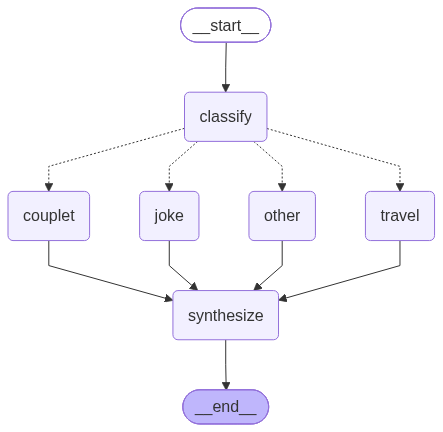

In [13]:
graph